# 16 来店の時刻・待ち時間・卓利用の整合性

全10店舗の来店ログを全件読み、到着・着席・注文・退店・離脱の順序、待ち・滞在時間、卓の定員、同一卓の利用時間の重なりを調べる。

ここで扱う来店は2022〜2024年の実績。ログに記録された状態・時刻の整合性を確認するもので、将来の来店時刻や空席を予測済みとして使わない。卓の利用は同日・同一店舗・同一 `table_id` の着席から退店までを対象とする。

In [1]:
from pathlib import Path
import zipfile,io
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'input').is_dir(): ROOT=ROOT.parent
assert (ROOT/'input').is_dir()
INPUT=ROOT/'input';sns.set_theme(style='whitegrid');pd.set_option('display.max_columns',40);pd.options.display.float_format='{:,.3f}'.format
stores=pd.read_csv(INPUT/'stores.csv')[['store_id','area_type']];store_ids=stores.store_id.tolist()
cols=['group_id','store_id','date','arrival_time','seat_time','order_time','departure_time','left_time','group_size','segment','queue_registered_flag','seat_source','table_id','table_capacity','wait_minutes','stay_minutes','left_reason','order_id','item_line_count','gross_sales_amount','discount_amount','net_sales_amount','is_seated','is_left']

## 状態・時刻の行単位検査
着席組は到着→着席→注文→退店、離脱組は到着→離脱。時刻差を分に変換し、記録された待ち・滞在時間と照らす。時刻の欠落や不正があれば、それぞれ別の検査に計上する。

In [2]:
summaries=[]; overlaps=[]; daily=[]; capacity_parts=[]; examples=[]
with zipfile.ZipFile(INPUT/'logs.zip') as z:
    for sid in store_ids:
        with z.open(f'logs/{sid}/visit_log.parquet') as f:
            v=pq.read_table(io.BytesIO(f.read()),columns=cols).to_pandas()
        seated=v.is_seated;left=v.is_left
        v['state_not_exclusive']=seated.eq(left)
        v['missing_arrival_or_date']=v.arrival_time.isna()|v.date.isna()
        v['arrival_date_mismatch']=v.arrival_time.dt.normalize().ne(v.date.dt.normalize()) & ~v.missing_arrival_or_date
        v['missing_seated_fields']=seated & (v.seat_time.isna()|v.order_time.isna()|v.departure_time.isna()|v.table_id.isna()|v.table_capacity.isna()|v.order_id.isna()|v.stay_minutes.isna())
        v['missing_left_fields']=left & v.left_time.isna()
        v['seated_bad_order']=seated & ((v.seat_time<v.arrival_time)|(v.order_time<v.seat_time)|(v.departure_time<v.order_time))
        v['left_before_arrival']=left & (v.left_time<v.arrival_time)
        calculated_wait=(v.seat_time.where(seated,v.left_time)-v.arrival_time).dt.total_seconds()/60
        calculated_stay=(v.departure_time-v.seat_time).dt.total_seconds()/60
        v['wait_mismatch']=v.wait_minutes.isna()|((calculated_wait-v.wait_minutes).abs()>1e-6)
        v['stay_mismatch']=seated & ((calculated_stay-v.stay_minutes).abs()>1e-6)
        v['over_capacity']=seated & (v.group_size>v.table_capacity)
        v['bad_money']=v.net_sales_amount.ne(v.gross_sales_amount-v.discount_amount)
        v['left_with_sales']=left & (v.net_sales_amount.ne(0)|v.item_line_count.ne(0)|v.order_id.notna())
        v['invalid_group_size']=v.group_size.le(0)
        issues=['state_not_exclusive','missing_arrival_or_date','arrival_date_mismatch','missing_seated_fields','missing_left_fields','seated_bad_order','left_before_arrival','wait_mismatch','stay_mismatch','over_capacity','bad_money','left_with_sales','invalid_group_size']
        count=v[issues].sum().to_dict();count.update(store_id=sid,rows=len(v),seated=int(seated.sum()),left=int(left.sum()));summaries.append(count)
        sample=v[v[issues].any(axis=1)].head(2)
        if len(sample):examples.append(sample.assign(source='row_check'))
        # 同じ店舗・日・卓で先行行の退店時刻の累積最大を使う。直前行だけを見ると長い滞在との重複を見落とす。
        use=v.loc[seated & v.table_id.notna() & v.seat_time.notna() & v.departure_time.notna(),['store_id','date','table_id','group_id','seat_time','departure_time']].sort_values(['store_id','date','table_id','seat_time','departure_time']).copy()
        key=['store_id','date','table_id'];running=use.groupby(key,observed=True).departure_time.cummax();previous=running.groupby([use[k] for k in key],observed=True).shift()
        use['overlap']=previous.gt(use.seat_time)
        overlaps.append({'store_id':sid,'seated_rows_checked':len(use),'same_table_overlaps':int(use.overlap.sum())})
        if use.overlap.any():examples.append(use[use.overlap].head(2).assign(source='table_overlap'))
        d=v.groupby(['store_id','date'],observed=True).agg(groups=('group_id','size'),seated=('is_seated','sum'),left=('is_left','sum'),guests=('group_size','sum'),wait_sum=('wait_minutes','sum')).reset_index()
        daily.append(d)
        capacity_parts.append(v[seated].groupby(['store_id','group_size','table_capacity'],observed=True).size().rename('groups').reset_index())
        print(sid,'来店行:',len(v),'卓重複:',int(use.overlap.sum()),flush=True)
        del v,use
checks=pd.DataFrame(summaries).set_index('store_id');table_check=pd.DataFrame(overlaps).set_index('store_id');daily=pd.concat(daily,ignore_index=True);capacity=pd.concat(capacity_parts,ignore_index=True)
display(checks);display(table_check)
print('全店舗の不一致・要確認件数:');display(checks.drop(columns=['rows','seated','left']).sum().to_frame('rows'))
print('卓の重なり件数:',int(table_check.same_table_overlaps.sum()))
if examples:display(pd.concat(examples,ignore_index=True).head(20))
assert checks.rows.sum()==2491880 and table_check.seated_rows_checked.sum()==checks.seated.sum()

S001 来店行: 335479 卓重複: 0
S002 来店行: 308798 卓重複: 0
S003 来店行: 255933 卓重複: 0
S004 来店行: 285398 卓重複: 0
S005 来店行: 214109 卓重複: 0
S006 来店行: 162109 卓重複: 0
S007 来店行: 193307 卓重複: 0
S008 来店行: 227188 卓重複: 0
S009 来店行: 151785 卓重複: 0
S010 来店行: 357774 卓重複: 0
全店舗の不一致・要確認件数:
卓の重なり件数: 0


,state_not_exclusive,missing_arrival_or_date,arrival_date_mismatch,missing_seated_fields,missing_left_fields,seated_bad_order,left_before_arrival,wait_mismatch,stay_mismatch,over_capacity,bad_money,left_with_sales,invalid_group_size,rows,seated,left
store_id,,,,,,,,,,,,,,,,
S001,0,0,0,0,0,0,0,0,0,0,0,0,0,335479,302739,32740
S002,0,0,0,0,0,0,0,0,0,0,0,0,0,308798,293032,15766
S003,0,0,0,0,0,0,0,0,0,0,0,0,0,255933,228881,27052
S004,0,0,0,0,0,0,0,0,0,0,0,0,0,285398,249291,36107
S005,0,0,0,0,0,0,0,0,0,0,0,0,0,214109,204652,9457
S006,0,0,0,0,0,0,0,0,0,0,0,0,0,162109,161552,557
S007,0,0,0,0,0,0,0,0,0,0,0,0,0,193307,190114,3193
S008,0,0,0,0,0,0,0,0,0,0,0,0,0,227188,225940,1248
S009,0,0,0,0,0,0,0,0,0,0,0,0,0,151785,150621,1164


,seated_rows_checked,same_table_overlaps
store_id,,
S001,302739,0
S002,293032,0
S003,228881,0
S004,249291,0
S005,204652,0
S006,161552,0
S007,190114,0
S008,225940,0
S009,150621,0


,rows
state_not_exclusive,0
missing_arrival_or_date,0
arrival_date_mismatch,0
missing_seated_fields,0
missing_left_fields,0
seated_bad_order,0
left_before_arrival,0
wait_mismatch,0
stay_mismatch,0
over_capacity,0


## 組人数と卓定員の組み合わせ
定員−人数は空いている席数。相席や卓の結合などはログに明示されていないため、単独の数値だけで非効率・誤りと判断しない。

着席組の平均未使用定員（人数単位）: 0.5444764922253946


table_capacity,1.000,2.000,4.000,6.000
group_size,,,,
1,469102,158434,49205,10253
2,0,808132,110115,24375
3,0,0,315818,46991
4,0,0,244691,40503
5,0,0,0,59863


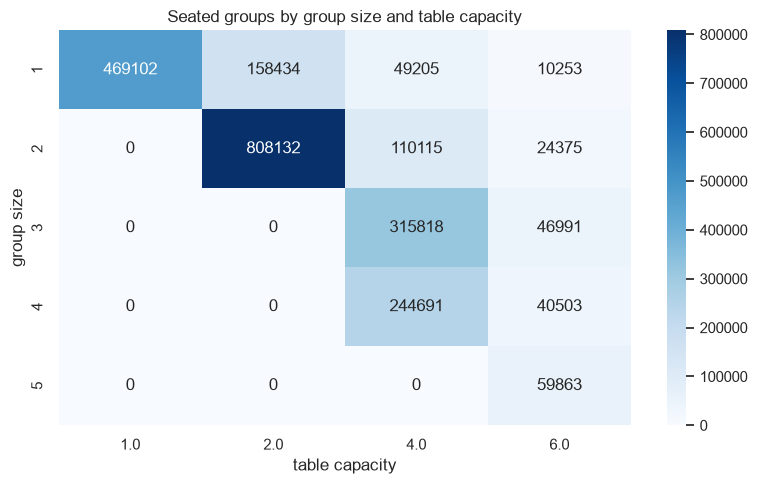

In [3]:
ct=capacity.groupby(['group_size','table_capacity'],observed=True)['groups'].sum().unstack(fill_value=0)
display(ct)
capacity['unused_seats']=capacity.table_capacity-capacity.group_size
print('着席組の平均未使用定員（人数単位）:',np.average(capacity.unused_seats,weights=capacity.groups))
fig,ax=plt.subplots(figsize=(8,5));sns.heatmap(ct.astype(float),annot=True,fmt='.0f',cmap='Blues',ax=ax);ax.set(title='Seated groups by group size and table capacity',xlabel='table capacity',ylabel='group size');plt.tight_layout();plt.show()

## 日・店舗ごとの離脱率と待ち時間
日単位での関連を示す。待ち時間は着席または離脱までの結果であり、どちらも同じ営業日の実績なので2025年同日の入力には使えない。

日×店舗数: 10960


,store_days,mean_groups,mean_left_rate,mean_wait
area_type,,,,
office,2192,244.519,0.027,1.145
residential,2192,162.142,0.009,0.359
roadside,2192,166.922,0.022,0.775
suburban_sc,2192,246.958,0.108,4.011
urban_core,2192,316.265,0.088,3.390


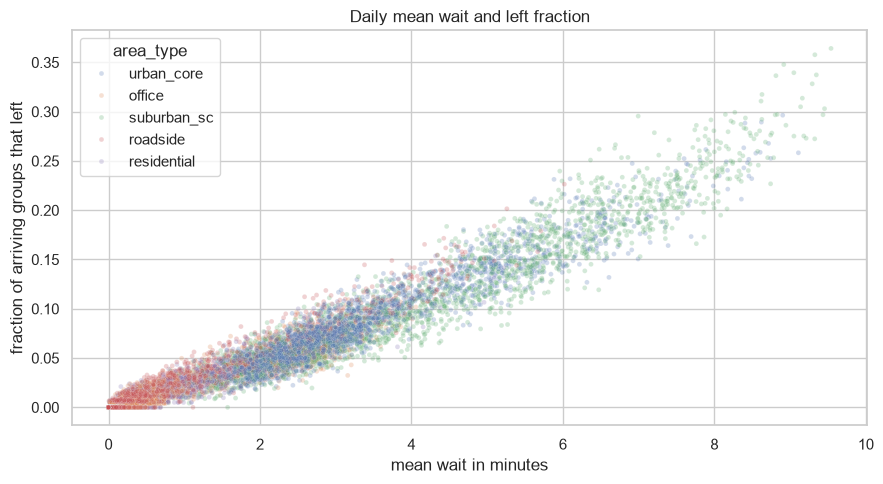

In [4]:
daily['left_rate']=daily.left/daily.groups;daily['mean_wait']=daily.wait_sum/daily.groups
daily=daily.merge(stores,on='store_id',validate='many_to_one')
print('日×店舗数:',len(daily))
display(daily.groupby('area_type').agg(store_days=('date','size'),mean_groups=('groups','mean'),mean_left_rate=('left_rate','mean'),mean_wait=('mean_wait','mean')))
fig,ax=plt.subplots(figsize=(9,5));sns.scatterplot(data=daily,x='mean_wait',y='left_rate',hue='area_type',alpha=.25,s=12,ax=ax);ax.set(title='Daily mean wait and left fraction',xlabel='mean wait in minutes',ylabel='fraction of arriving groups that left');plt.tight_layout();plt.show()

## 解釈の注意
- 時刻や卓の整合性は配布済みの履歴に対する検査結果。予測期間の記録は存在しない。
- 同一卓の重複は同日・同一卓の時間区間に限り検査し、日をまたぐ利用はこの検査に含めない。
- 日次の待ちと離脱の関係は相関であり、客層・曜日・席構成・混雑などが関係する。待ち時間を短くした場合の因果効果ではない。